# option-pricer: walkthrough

This notebook runs every method of the package on one example and plots the results.
Inputs throughout: at-the-money option, S = K = 100, T = 1 year, r = 5%, volatility 20%, no dividend.

1. Black-Scholes price and Greeks
2. Implied volatility
3. Monte Carlo with antithetic variates, control variate and 95% confidence interval
4. American options: CRR binomial tree and Longstaff-Schwartz Monte Carlo

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))  # run from notebooks/
from option_pricer import bs_price, bs_greeks, implied_vol, mc_price, crr_price, lsm_price

S, K, T, r, sigma = 100.0, 100.0, 1.0, 0.05, 0.20
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

## 1. Black-Scholes price and Greeks

Closed-form price of a European option and its analytical sensitivities. In Python, vega and rho are per
1.00 change and theta per year; below they are converted to desk units (per vol point, per rate point,
per calendar day).

In [2]:
for kind in ("call", "put"):
    g = bs_greeks(S, K, T, r, sigma, kind)
    print(f"{kind:4s}  price {g.price:8.4f} | delta {g.delta:+.4f} | gamma {g.gamma:.4f} | "
          f"vega {g.vega / 100:.4f} | theta/day {g.theta / 365:+.4f} | rho {g.rho / 100:+.4f}")

call, put = bs_price(S, K, T, r, sigma, "call"), bs_price(S, K, T, r, sigma, "put")
print(f"Put-call parity check: C - P = {call - put:.6f}, S - K e^(-rT) = {S - K * np.exp(-r * T):.6f}")

call  price  10.4506 | delta +0.6368 | gamma 0.0188 | vega 0.3752 | theta/day -0.0176 | rho +0.5323
put   price   5.5735 | delta -0.3632 | gamma 0.0188 | vega 0.3752 | theta/day -0.0045 | rho -0.4189
Put-call parity check: C - P = 4.877058, S - K e^(-rT) = 4.877058


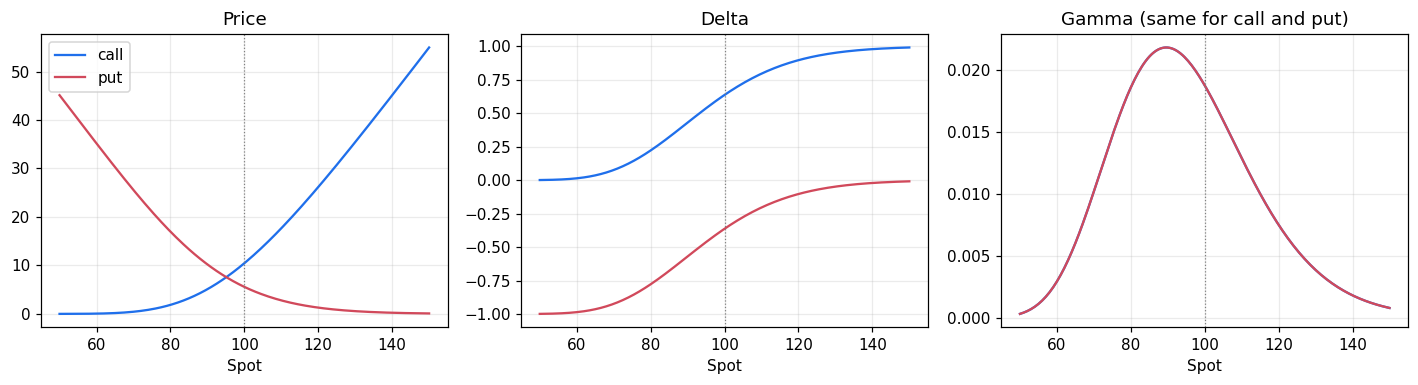

In [3]:
spots = np.linspace(50, 150, 201)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for kind, color in (("call", "#1f6feb"), ("put", "#d1495b")):
    gs = [bs_greeks(s, K, T, r, sigma, kind) for s in spots]
    axes[0].plot(spots, [g.price for g in gs], color=color, label=kind)
    axes[1].plot(spots, [g.delta for g in gs], color=color, label=kind)
    axes[2].plot(spots, [g.gamma for g in gs], color=color, label=kind)
for ax, title in zip(axes, ("Price", "Delta", "Gamma (same for call and put)")):
    ax.set_title(title); ax.set_xlabel("Spot"); ax.axvline(K, color="grey", lw=0.8, ls=":")
axes[0].legend()
plt.tight_layout()

## 2. Implied volatility

Inverse problem: find the volatility that reproduces a given price. Newton-Raphson on vega, with a
bisection fallback when Newton leaves the bracket (deep in or out of the money).

Implied vol of the BS call price 10.4506: 0.200000
Max round-trip error over 17 strikes: 2.75e-11


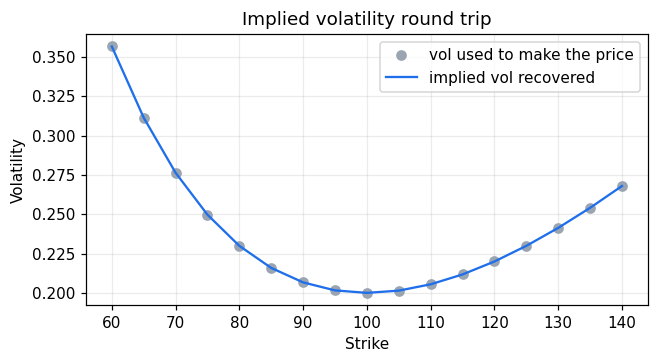

In [4]:
print(f"Implied vol of the BS call price {call:.4f}: {implied_vol(call, S, K, T, r, 'call'):.6f}")

# Round trip on a strike grid with a volatility smile, to show the solver is robust
strikes = np.arange(60, 145, 5.0)
true_vols = 0.20 + 0.6 * (np.log(strikes / S)) ** 2
prices = [bs_price(S, k, T, r, v, "call") for k, v in zip(strikes, true_vols)]
recovered = [implied_vol(p, S, k, T, r, "call") for p, k in zip(prices, strikes)]
print(f"Max round-trip error over {len(strikes)} strikes: {np.max(np.abs(np.array(recovered) - true_vols)):.2e}")

plt.figure(figsize=(6, 3.4))
plt.plot(strikes, true_vols, "o", color="#9aa5b1", label="vol used to make the price")
plt.plot(strikes, recovered, "-", color="#1f6feb", label="implied vol recovered")
plt.xlabel("Strike"); plt.ylabel("Volatility"); plt.title("Implied volatility round trip"); plt.legend()
plt.tight_layout()

## 3. Monte Carlo

The terminal spot is simulated exactly under geometric Brownian motion, the payoff is averaged and
discounted. Two variance reduction techniques:

- **antithetic variates**: each draw Z is paired with -Z;
- **control variate**: the discounted terminal spot, whose mean is known exactly (S e^(-qT)).

The result carries a standard error and a 95% confidence interval.

In [5]:
for label, anti, cv in [("plain", False, False), ("antithetic", True, False),
                        ("antithetic + control variate", True, True)]:
    res = mc_price(S, K, T, r, sigma, "call", n_paths=100_000, antithetic=anti, control_variate=cv, seed=0)
    print(f"{label:30s} {res}   std error {res.std_error:.4f}")
print(f"{'Black-Scholes':30s} {call:.4f}")

plain                          10.4362 +/- 0.0912 (95% CI [10.3450, 10.5273], n=100000)   std error 0.0465
antithetic                     10.4721 +/- 0.0645 (95% CI [10.4076, 10.5367], n=100000)   std error 0.0329
antithetic + control variate   10.4577 +/- 0.0172 (95% CI [10.4405, 10.4750], n=100000)   std error 0.0088
Black-Scholes                  10.4506


Empirical coverage of the 95% CI: 95.5% (expected about 95%)


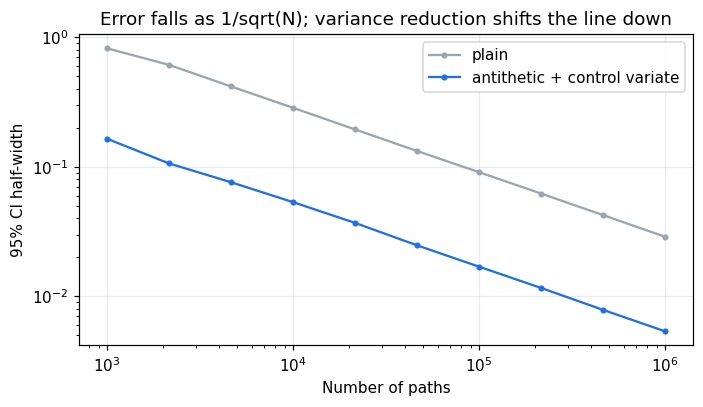

In [6]:
# How often does the 95% interval contain the true price? 200 independent runs of 20,000 paths
hits = [mc_price(S, K, T, r, sigma, "call", n_paths=20_000, seed=i) for i in range(200)]
coverage = np.mean([h.ci_low <= call <= h.ci_high for h in hits])
print(f"Empirical coverage of the 95% CI: {coverage:.1%} (expected about 95%)")

ns = np.unique(np.logspace(3, 6, 10).astype(int))
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for label, anti, cv, color in [("plain", False, False, "#9aa5b1"),
                               ("antithetic + control variate", True, True, "#1f6feb")]:
    hw = [1.96 * mc_price(S, K, T, r, sigma, "call", n_paths=int(n), antithetic=anti,
                          control_variate=cv, seed=7).std_error for n in ns]
    ax.loglog(ns, hw, "o-", ms=3, color=color, label=label)
ax.set_xlabel("Number of paths"); ax.set_ylabel("95% CI half-width")
ax.set_title("Error falls as 1/sqrt(N); variance reduction shifts the line down")
ax.legend(); plt.tight_layout()

## 4. American options

An American put can be exercised early, so it is worth more than the European put. Two methods:

- **CRR binomial tree**: backward induction, exercise checked at every node;
- **Longstaff-Schwartz (LSM)**: Monte Carlo paths, the continuation value is estimated by a regression on
  the spot at each exercise date.

Benchmark from Longstaff & Schwartz (2001), Table 1: S = 36, K = 40, r = 6%, vol = 20%, T = 1.

In [7]:
eu = bs_price(36, 40, 1, 0.06, 0.20, "put")
for n in (100, 500, 1000, 5000, 20000):
    print(f"CRR {n:>6d} steps: {crr_price(36, 40, 1, 0.06, 0.20, 'put', steps=n, american=True):.4f}")
lsm = lsm_price(36, 40, 1, 0.06, 0.20, "put", n_paths=100_000, steps=50, seed=1)
print(f"LSM 100,000 paths, 50 exercise dates: {lsm}")
print(f"European put (BS): {eu:.4f}")
print("Paper: finite differences 4.478, LSM 4.472 (s.e. 0.010)")

CRR    100 steps: 4.4880
CRR    500 steps: 4.4864
CRR   1000 steps: 4.4868


CRR   5000 steps: 4.4867


CRR  20000 steps: 4.4867


LSM 100,000 paths, 50 exercise dates: 4.4751 +/- 0.0118 (95% CI [4.4633, 4.4869], n=100000)
European put (BS): 3.8443
Paper: finite differences 4.478, LSM 4.472 (s.e. 0.010)


The tree is stable at **4.4867** from 1,000 steps on: this is the converged value. The paper's 4.478
comes from a coarser finite-difference grid, and its LSM figure (4.472) has a standard error of 0.010.
Our LSM estimate lands within about two standard errors of the tree; LSM is also slightly biased low
because the exercise rule is estimated, not optimal.

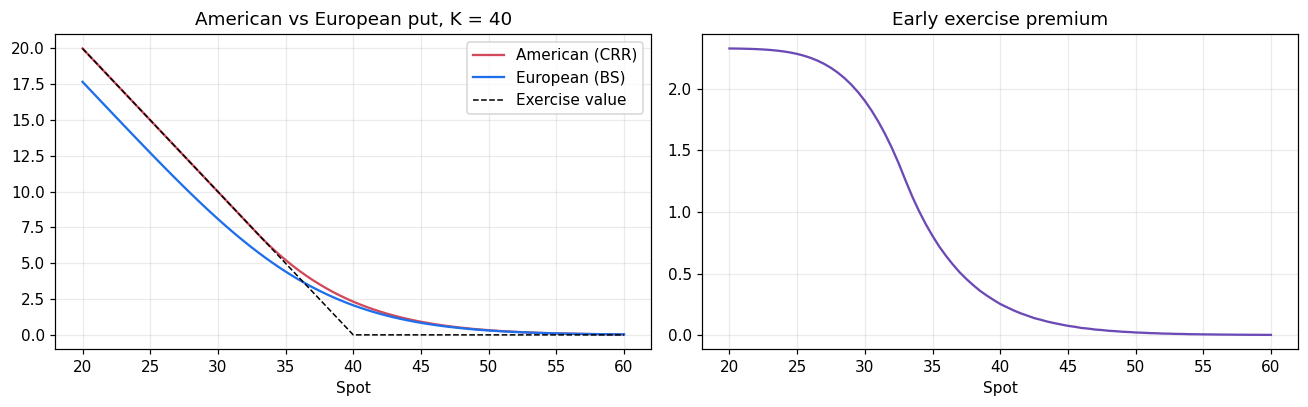

In [8]:
spots = np.linspace(20, 60, 81)
am = [crr_price(s, 40, 1, 0.06, 0.20, "put", steps=400, american=True) for s in spots]
eu = [bs_price(s, 40, 1, 0.06, 0.20, "put") for s in spots]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
ax1.plot(spots, am, color="#d1495b", label="American (CRR)")
ax1.plot(spots, eu, color="#1f6feb", label="European (BS)")
ax1.plot(spots, np.maximum(40 - spots, 0), "k--", lw=1, label="Exercise value")
ax1.set_xlabel("Spot"); ax1.set_title("American vs European put, K = 40"); ax1.legend()
ax2.plot(spots, np.array(am) - np.array(eu), color="#6c4ab6")
ax2.set_xlabel("Spot"); ax2.set_title("Early exercise premium")
plt.tight_layout()

## Summary

| Method | Result on the examples above |
|---|---|
| Black-Scholes ATM call / put | 10.4506 / 5.5735 |
| Implied vol round trip | error below 1e-8 |
| Monte Carlo, 100,000 paths, antithetic + CV | standard error about 5x smaller than plain MC |
| American put (S=36, K=40), CRR / LSM | 4.4867 / about 4.475 |

Limits: constant volatility and rates, vanilla payoffs only. See the README for details.